## 3. Gaussian Mixture Models

In [1]:
# Imports necessary libraries.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import hashlib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import silhouette_score
from scipy.stats import multivariate_normal
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture

# Generate seed based on my college ID.
username = "sudhanva.joshi"
seed = int(hashlib.sha256(username.encode()).hexdigest(), 16) % (2**32)
print("Seed generated:", seed)
rng = np.random.default_rng(seed)

# Set plotting theme and helper functons.
sns.set_theme(context="paper", style="darkgrid",
              palette="rocket", font="Nimbus Roman")

def plotinfo(title, x, y, userid=username):
    plt.text(0.95, -0.1, userid, ha="right", va="top",
             transform=plt.gca().transAxes, fontsize=10,
             color="gray", alpha=0.7)
    plt.title(title, fontsize=14, fontweight='bold')
    plt.xlabel(x, fontsize=12)
    plt.ylabel(y, fontsize=12)
    plt.tight_layout()
    plt.show()

def coordplot(ax, title, x_label, y_label):
    ax.set_title(title)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)


# Loaded and Preprocessed the Data.
df = pd.read_csv("data/clustering_dataset.csv")

missing_count = df['Genre'].isnull().sum()
choices = ['Male', 'Female']
random_genres = rng.choice(choices, size=missing_count)
df.loc[df['Genre'].isnull(), 'Genre'] = random_genres

numerical_cols = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

genre_dummies = pd.get_dummies(df['Genre'], prefix='Genre')
df_processed = pd.concat([df.drop('Genre', axis=1), genre_dummies], axis=1)


#    (CustomerID is excluded as it's an identifier)
features = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)', 'Genre_Female', 'Genre_Male']
X = df_processed[features].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Successfully created X_scaled.")
print("Shape of X_scaled:", X_scaled.shape)
print("First 5 rows of X_scaled:\n", X_scaled[:5])

Seed generated: 1027714457
Successfully created X_scaled.
Shape of X_scaled: (200, 5)
First 5 rows of X_scaled:
 [[-1.42602061 -1.76824502 -0.44100336 -1.1055416   1.1055416 ]
 [-1.28087856  0.04435075  1.19234243 -1.1055416   1.1055416 ]
 [-1.35344959 -1.72967915 -1.72434649  0.90453403 -0.90453403]
 [-1.13573652 -1.72967915  1.03678569  0.90453403 -0.90453403]
 [-0.55516833 -1.69111328 -0.40211418  0.90453403 -0.90453403]]


### 3.1 Implement the GMM Class

In [2]:
class GMM:
    """
    A Gaussian Mixture Model implementation from scratch using the EM algorithm.
    """
    def __init__(self, k, max_iter=100, tol=1e-4):
        self.k = k
        self.max_iter = max_iter
        self.tol = tol  # Tolerance for convergence
        self.pi = None  # Mixing coefficients
        self.mu = None  # Means of the Gaussians
        self.sigma = None # Covariance matrices of the Gaussians
        self.likelihood_history = []
        self.responsibilities = None

    def _initialize_parameters(self, X):
        """Initializes model parameters."""
        n_samples, n_features = X.shape
        self.pi = np.full(self.k, 1/self.k)
        random_indices = rng.choice(n_samples, self.k, replace=False)
        self.mu = X[random_indices]
        self.sigma = np.array([np.eye(n_features)] * self.k)

    def _e_step(self, X):
        """Performs the Expectation (E) step."""
        n_samples = X.shape[0]
        self.responsibilities = np.zeros((n_samples, self.k))
        for i in range(self.k):
            pdf = multivariate_normal.pdf(X, mean=self.mu[i], cov=self.sigma[i], allow_singular=True)
            self.responsibilities[:, i] = self.pi[i] * pdf
        
        # Add a small constant to prevent division by zero
        sum_resp = np.sum(self.responsibilities, axis=1, keepdims=True)
        self.responsibilities = self.responsibilities / (sum_resp + 1e-9)

    def _m_step(self, X):
        """Performs the Maximization (M) step."""
        n_samples, n_features = X.shape
        Nk = np.sum(self.responsibilities, axis=0)
        
        self.pi = Nk / n_samples
        self.mu = (self.responsibilities.T @ X) / (Nk[:, np.newaxis] + 1e-9)
        
        for i in range(self.k):
            diff = X - self.mu[i]
            # Add a small epsilon for numerical stability
            epsilon = 1e-6 * np.eye(n_features)
            self.sigma[i] = (diff.T * self.responsibilities[:, i]) @ diff / (Nk[i] + 1e-9) + epsilon

    def _calculate_log_likelihood(self, X):
        """Calculates the log-likelihood of the data."""
        likelihood = np.zeros(X.shape[0])
        for i in range(self.k):
            pdf = multivariate_normal.pdf(X, mean=self.mu[i], cov=self.sigma[i], allow_singular=True)
            likelihood += self.pi[i] * pdf
        return np.sum(np.log(likelihood + 1e-9))
        
    def fit(self, X):
        """Fits the GMM to the dataset X using the EM algorithm."""
        self._initialize_parameters(X)
        for i in range(self.max_iter):
            self._e_step(X)
            self._m_step(X)
            log_likelihood = self._calculate_log_likelihood(X)
            self.likelihood_history.append(log_likelihood)
            
            if i > 0 and abs(log_likelihood - self.likelihood_history[-2]) < self.tol:
                print(f"Converged at iteration {i+1}.")
                break
        else:
             print(f"Reached max iterations ({self.max_iter}) without convergence.")

    def getMembership(self):
        """Returns the membership values (responsibilities) Y_ic."""
        if self.responsibilities is None:
            raise ValueError("Model has not been fitted yet. Call fit() first.")
        return self.responsibilities

    def getLikelihood(self):
        """Returns the final log-likelihood of the dataset."""
        if not self.likelihood_history:
            raise ValueError("Model has not been fitted yet. Call fit() first.")
        return self.likelihood_history[-1]

    def drawLikelihood(self):
        """Plots the log-likelihood vs. iteration."""
        plt.figure(figsize=(10, 6))
        plt.plot(range(1, len(self.likelihood_history) + 1), self.likelihood_history, marker='o')
        plotinfo(f'Log-Likelihood vs. Iteration for k={self.k}', 'Iteration', 'Log-Likelihood')

### 3.2 Determine the Optimal Number of Clusters

#### BIC (Bayesian Information Criterion)

- The BIC scores are plotted against different values of *k*.  
- A sharp improvement is observed at **k = 3**, where the BIC score is maximized.  
- After this point, the BIC values steadily decline, suggesting that adding more clusters does not improve model fit.  

According to the BIC method, the **optimal number of clusters is k = 3**.

#### Silhouette Method

- The silhouette scores are plotted for values of *k* from 2 to 10.  
- The highest average silhouette score occurs at **k = 2**, with a secondary peak at **k = 3**.  
- Beyond k = 3, the silhouette scores generally decline, indicating less well-defined clusters.  

According to the Silhouette method, the **optimal number of clusters is k = 2 (or possibly k = 3 as a trade-off)**.


Converged at iteration 62.


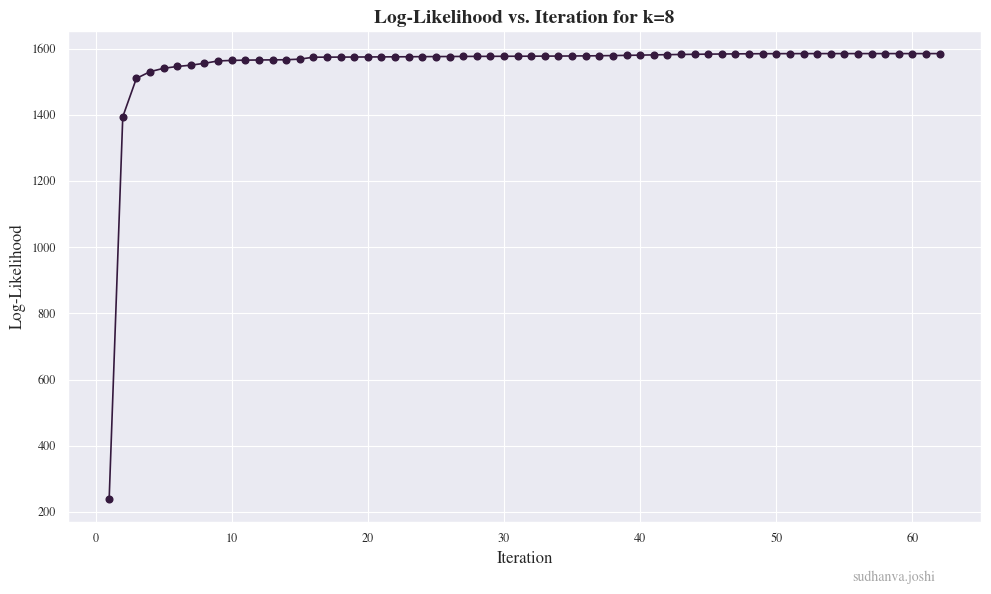

In [3]:
k_demo = 8
gmm_custom = GMM(k=k_demo, max_iter=150)
gmm_custom.fit(X_scaled)
gmm_custom.drawLikelihood()

### BIC (Bayesian Information Criterion) 

Calculating for k=2...
Converged at iteration 4.
Calculating for k=3...
Converged at iteration 24.
Calculating for k=4...
Converged at iteration 15.
Calculating for k=5...
Converged at iteration 27.
Calculating for k=6...
Converged at iteration 66.
Calculating for k=7...
Converged at iteration 39.
Calculating for k=8...
Converged at iteration 28.
Calculating for k=9...
Converged at iteration 30.
Calculating for k=10...
Converged at iteration 38.
Calculating for k=11...
Converged at iteration 68.
Calculating for k=12...
Converged at iteration 82.
Calculating for k=13...
Converged at iteration 59.
Calculating for k=14...
Converged at iteration 93.
Calculating for k=15...
Converged at iteration 38.


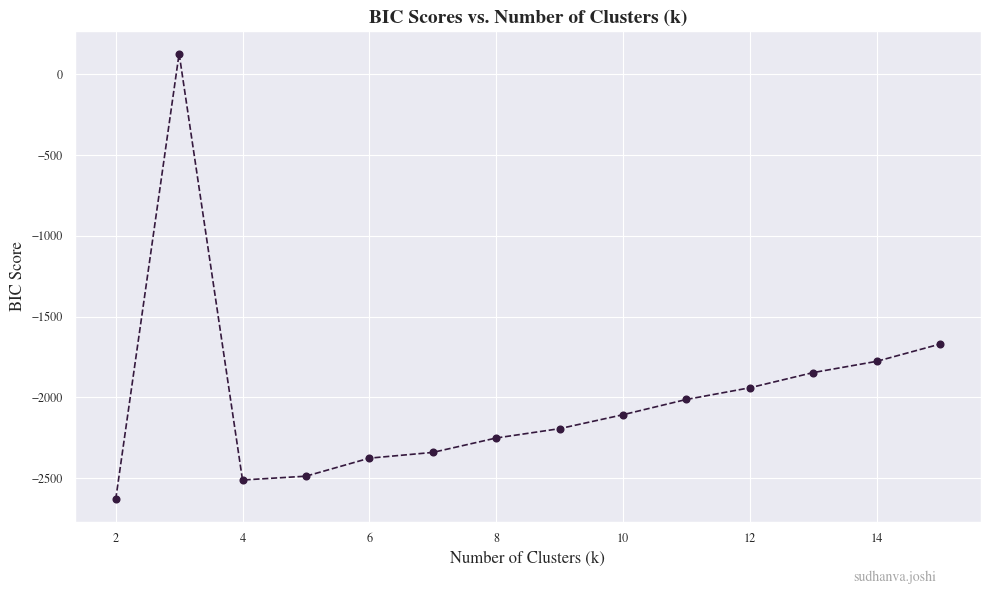

In [4]:
bic_scores = []
k_range = range(2, 16)
n_samples, n_features = X_scaled.shape

for k in k_range:
    print(f"Calculating for k={k}...")
    # 1. Fit your custom GMM
    gmm_custom = GMM(k=k, max_iter=150)
    gmm_custom.fit(X_scaled)
    
    # 2. Get the log-likelihood
    log_likelihood = gmm_custom.getLikelihood()
    
    # 3. Calculate the number of free parameters (p)
    # Means (k*d) + Covariances (k*d*(d+1)/2) + Mixing Coeffs (k-1)
    n_params = (k * n_features) + (k * n_features * (n_features + 1) / 2) + (k - 1)
    
    # 4. Calculate BIC
    bic = n_params * np.log(n_samples) - 2 * log_likelihood
    bic_scores.append(bic)

# Plot the results
plt.figure(figsize=(10, 6))
plt.plot(k_range, bic_scores, marker='o', linestyle='--')
plotinfo('BIC Scores vs. Number of Clusters (k)', 'Number of Clusters (k)', 'BIC Score')

Calculating for k=2...
Converged at iteration 5.
Calculating for k=3...
Converged at iteration 38.
Calculating for k=4...
Converged at iteration 20.
Calculating for k=5...
Converged at iteration 24.
Calculating for k=6...
Converged at iteration 33.
Calculating for k=7...


Converged at iteration 69.
Calculating for k=8...
Converged at iteration 54.
Calculating for k=9...
Converged at iteration 126.
Calculating for k=10...
Converged at iteration 43.


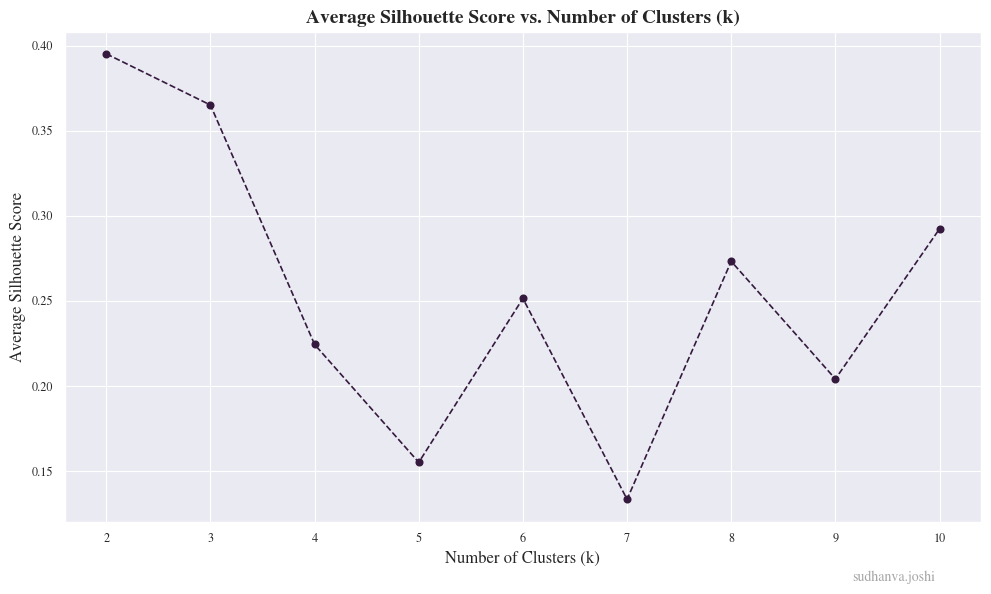

In [5]:
silhouette_scores = []
k_range = range(2, 11)

for k in k_range:
    print(f"Calculating for k={k}...")
    # 1. Fit your custom GMM
    gmm_custom = GMM(k=k, max_iter=150)
    gmm_custom.fit(X_scaled)
    
    # 2. Get the membership probabilities
    responsibilities = gmm_custom.getMembership()
    
    # 3. Assign cluster labels based on the highest probability
    labels = np.argmax(responsibilities, axis=1)
    
    # 4. Calculate the silhouette score with these labels
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

# Plot the results
plt.figure(figsize=(10, 6))
plt.plot(k_range, silhouette_scores, marker='o', linestyle='--')
plotinfo('Average Silhouette Score vs. Number of Clusters (k)', 'Number of Clusters (k)', 'Average Silhouette Score')